
# System Cold Start in Hybrid Movie Recommendation System

## Objective

To develop a recommendation mechanism for a newly launched movie recommendation platform with no historical user-movie interactions.

The system initially relies on movie metadata and user onboarding preferences to generate recommendations. As user interactions gradually become available, collaborative filtering is introduced and integrated with content-based filtering to improve recommendation quality.

## Experimental Workflow

1. Simulate a new platform with zero interactions.
2. Generate content-based recommendations using movie metadata.
3. Simulate gradual collection of user interactions.
4. Introduce collaborative filtering as interaction data increases.
5. Integrate content-based and collaborative filtering.
6. Evaluate recommendation performance at different platform growth stages.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)

print("Libraries imported successfully!")


Libraries imported successfully!


In [16]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "dataset" / "processed"

ratings = pd.read_csv(DATA_DIR / "ratings_clean.csv")

print("Ratings loaded successfully!")
print("Shape:", ratings.shape)
ratings.head()

Ratings loaded successfully!
Shape: (855598, 9)


,userID,movieID,rating,date_day,date_month,date_year,date_hour,date_minute,date_second
0,75,3,1.0,29,10,2006,23,17,16
1,75,32,4.5,29,10,2006,23,23,44
2,75,110,4.0,29,10,2006,23,30,8
3,75,160,2.0,29,10,2006,23,16,52
4,75,163,4.0,29,10,2006,23,29,30


In [17]:
from sklearn.model_selection import train_test_split

train_parts = []
test_parts = []

for user_id, group in ratings.groupby("userID"):
    if len(group) < 2:
        train_parts.append(group)
    else:
        train_user, test_user = train_test_split(
            group,
            test_size=0.2,
            random_state=42
        )

        train_parts.append(train_user)
        test_parts.append(test_user)

train_ratings = pd.concat(train_parts, ignore_index=True)
test_ratings = pd.concat(test_parts, ignore_index=True)

print("Training interactions:", len(train_ratings))
print("Testing interactions:", len(test_ratings))

Training interactions: 683631
Testing interactions: 171967


In [18]:
print("Training users:", train_ratings["userID"].nunique())
print("Testing users:", test_ratings["userID"].nunique())

print(
    "Users missing from training:",
    len(set(test_ratings["userID"]) - set(train_ratings["userID"]))
)

print(
    "Movies missing from training:",
    len(set(test_ratings["movieID"]) - set(train_ratings["movieID"]))
)

Training users: 2113
Testing users: 2113
Users missing from training: 0
Movies missing from training: 137


In [19]:
train_ratings.to_csv(
    DATA_DIR / "train_ratings.csv",
    index=False
)

test_ratings.to_csv(
    DATA_DIR / "test_ratings.csv",
    index=False
)

print("Train and test datasets saved successfully!")

Train and test datasets saved successfully!


In [20]:
print("Training users:", train_ratings["userID"].nunique())
print("Testing users:", test_ratings["userID"].nunique())

print(
    "Users missing from training:",
    len(set(test_ratings["userID"]) - set(train_ratings["userID"]))
)

print(
    "Movies missing from training:",
    len(set(test_ratings["movieID"]) - set(train_ratings["movieID"]))
)

Training users: 2113
Testing users: 2113
Users missing from training: 0
Movies missing from training: 137


In [21]:
# Get movies available in training data
train_movie_ids = set(train_ratings["movieID"])

# Keep only test interactions for movies present in training
test_ratings = test_ratings[
    test_ratings["movieID"].isin(train_movie_ids)
].copy()

test_ratings.reset_index(drop=True, inplace=True)

print("Updated test interactions:", len(test_ratings))

print(
    "Movies missing from training:",
    len(set(test_ratings["movieID"]) - train_movie_ids)
)

Updated test interactions: 171808
Movies missing from training: 0


In [22]:
train_ratings.to_csv(
    DATA_DIR / "train_ratings.csv",
    index=False
)

test_ratings.to_csv(
    DATA_DIR / "test_ratings.csv",
    index=False
)

print("Train and test datasets saved successfully!")

Train and test datasets saved successfully!


In [23]:
print("Train file exists:", (DATA_DIR / "train_ratings.csv").exists())
print("Test file exists:", (DATA_DIR / "test_ratings.csv").exists())


Train file exists: True
Test file exists: True


## 1. Simulating a New Recommendation Platform

A system cold-start scenario occurs when a recommendation platform is newly launched and has no historical user-item interactions.

In this experiment, the platform starts with an existing movie catalogue containing metadata such as genres, tags, actors, directors and countries. However, no user ratings or interaction history are initially available.

Therefore, collaborative filtering cannot be applied at the initial stage.

In [24]:
# Load movie metadata

movie_features = pd.read_csv(DATA_DIR / "movie_features.csv")

print("Movie catalogue loaded successfully!")
print("Total movies:", len(movie_features))
print("Unique movie IDs:", movie_features["movieID"].nunique())

movie_features.head()

Movie catalogue loaded successfully!
Total movies: 10197
Unique movie IDs: 10197


,movieID,title,imdbID,spanishTitle,imdbPictureURL,year,rtID,rtAllCriticsRating,rtAllCriticsNumReviews,rtAllCriticsNumFresh,...,rtAudienceRating,rtAudienceNumRatings,rtAudienceScore,rtPictureURL,genres,tags,actors,directors,countries,content
0,1,Toy story,114709,Toy story (juguetes),http://ia.media-imdb.com/images/M/MV5BMTMwNDU0...,1995,toy_story,9,73,73,...,3.7,102338,81,http://content7.flixster.com/movie/10/93/63/10...,Adventure Animation Children Comedy Fantasy,animation pixar disney toys computer animation...,Tom Hanks Tim Allen Don Rickles Jim Varney Wal...,John Lasseter,USA,Adventure Animation Children Comedy Fantasy an...
1,2,Jumanji,113497,Jumanji,http://ia.media-imdb.com/images/M/MV5BMzM5NjE1...,1995,1068044-jumanji,5.6,28,13,...,3.2,44587,61,http://content8.flixster.com/movie/56/79/73/56...,Adventure Children Fantasy,robin williams animals fantasy board game time...,Robin Williams Bonnie Hunt Kirsten Dunst Bradl...,Joe Johnston,USA,Adventure Children Fantasy robin williams anim...
2,3,Grumpy Old Men,107050,Dos viejos gruñones,http://ia.media-imdb.com/images/M/MV5BMTI5MTgy...,1993,grumpy_old_men,5.9,36,24,...,3.2,10489,66,http://content6.flixster.com/movie/25/60/25602...,Comedy Romance,old funniest movies sequel fever jack lemmon w...,Jack Lemmon Walter Matthau Ann-Margret Burgess...,Donald Petrie,USA,Comedy Romance old funniest movies sequel feve...
3,4,Waiting to Exhale,114885,Esperando un respiro,http://ia.media-imdb.com/images/M/MV5BMTczMTMy...,1995,waiting_to_exhale,5.6,25,14,...,3.3,5666,79,http://content9.flixster.com/movie/10/94/17/10...,Comedy Drama Romance,NaN,Whitney Houston Angela Bassett Loretta Devine ...,Forest Whitaker,USA,Comedy Drama Romance Whitney Houston Angela B...
4,5,Father of the Bride Part II,113041,Vuelve el padre de la novia (Ahora también abu...,http://ia.media-imdb.com/images/M/MV5BMTg1NDc2...,1995,father_of_the_bride_part_ii,5.3,19,9,...,3,13761,64,http://content8.flixster.com/movie/25/54/25542...,Comedy,family wedding pregnancy childhood classics se...,Steve Martin Diane Keaton Martin Short Kimberl...,Charles Shyer,USA,Comedy family wedding pregnancy childhood clas...


In [25]:
# Simulate a newly launched platform

platform_ratings = pd.DataFrame(
    columns=ratings.columns
)

print("Platform launched successfully!")
print("Total interactions:", len(platform_ratings))
print("Collaborative filtering available:", len(platform_ratings) > 0)

Platform launched successfully!
Total interactions: 0
Collaborative filtering available: False


In [26]:
print("SYSTEM COLD START STATUS")
print("------------------------")
print("Movie catalogue:", len(movie_features))
print("User interactions:", len(platform_ratings))
print("User history available:", len(platform_ratings) > 0)
print("Recommendation method: Content-Based Filtering")

SYSTEM COLD START STATUS
------------------------
Movie catalogue: 10197
User interactions: 0
User history available: False
Recommendation method: Content-Based Filtering


## 2. Movie Feature Extraction Using TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) converts textual movie metadata into numerical feature vectors.

The term frequency measures how frequently a word appears in a movie's description, while inverse document frequency reduces the importance of words that appear across many movies.

These vectors allow the system to identify similarities between movies based on their metadata rather than user ratings.

In [27]:
# Inspect movie content

print("Available columns:")
print(movie_features.columns.tolist())

print("\nMissing content values:")
print(movie_features["content"].isna().sum())

print("\nSample movie content:")
movie_features[["title", "genres", "tags", "content"]].head(5)

Available columns:
['movieID', 'title', 'imdbID', 'spanishTitle', 'imdbPictureURL', 'year', 'rtID', 'rtAllCriticsRating', 'rtAllCriticsNumReviews', 'rtAllCriticsNumFresh', 'rtAllCriticsNumRotten', 'rtAllCriticsScore', 'rtTopCriticsRating', 'rtTopCriticsNumReviews', 'rtTopCriticsNumFresh', 'rtTopCriticsNumRotten', 'rtTopCriticsScore', 'rtAudienceRating', 'rtAudienceNumRatings', 'rtAudienceScore', 'rtPictureURL', 'genres', 'tags', 'actors', 'directors', 'countries', 'content']

Missing content values:
0

Sample movie content:


,title,genres,tags,content
0,Toy story,Adventure Animation Children Comedy Fantasy,animation pixar disney toys computer animation...,Adventure Animation Children Comedy Fantasy an...
1,Jumanji,Adventure Children Fantasy,robin williams animals fantasy board game time...,Adventure Children Fantasy robin williams anim...
2,Grumpy Old Men,Comedy Romance,old funniest movies sequel fever jack lemmon w...,Comedy Romance old funniest movies sequel feve...
3,Waiting to Exhale,Comedy Drama Romance,NaN,Comedy Drama Romance Whitney Houston Angela B...
4,Father of the Bride Part II,Comedy,family wedding pregnancy childhood classics se...,Comedy family wedding pregnancy childhood clas...


In [28]:
# Handle missing and empty content

movie_features["content"] = (
    movie_features["content"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Check movies with available metadata
movies_with_content = (
    movie_features["content"].str.len() > 0
).sum()

print("Movies with content:", movies_with_content)
print("Movies without content:", len(movie_features) - movies_with_content)

Movies with content: 10197
Movies without content: 0


In [29]:
# Initialize TF-IDF vectorizer

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

# Convert movie content into numerical vectors
tfidf_matrix = tfidf_vectorizer.fit_transform(
    movie_features["content"]
)

print("TF-IDF transformation completed!")
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of unique terms:", len(tfidf_vectorizer.vocabulary_))

TF-IDF transformation completed!
TF-IDF matrix shape: (10197, 10000)
Number of unique terms: 10000


In [30]:
print("Matrix type:", type(tfidf_matrix))
print("Matrix dimensions:", tfidf_matrix.shape)
print("Non-zero values:", tfidf_matrix.nnz)
print("Sparsity:", 
      round(
          100 * (1 - tfidf_matrix.nnz /
                 (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])),
          2
      ), "%"
)

Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix dimensions: (10197, 10000)
Non-zero values: 328581
Sparsity: 99.68 %


In [31]:
# Create a mapping between movie IDs and matrix row indices
movie_id_to_index = pd.Series(
    movie_features.index,
    index=movie_features["movieID"]
).to_dict()

movie_index_to_id = {
    index: movie_id
    for movie_id, index in movie_id_to_index.items()
}

print("Movie lookup created successfully!")
print("Total movies indexed:", len(movie_id_to_index))

Movie lookup created successfully!
Total movies indexed: 10197


In [32]:
from sklearn.metrics.pairwise import cosine_similarity

def recommend_similar_movies(movie_id, top_n=10):

    if movie_id not in movie_id_to_index:
        print("Movie ID not found!")
        return pd.DataFrame()

    movie_index = movie_id_to_index[movie_id]

    # Calculate similarity with all movies
    similarity_scores = cosine_similarity(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    # Get indices of most similar movies
    similar_indices = np.argsort(similarity_scores)[::-1]

    # Exclude the movie itself
    similar_indices = [
        idx for idx in similar_indices
        if idx != movie_index
    ][:top_n]

    recommendations = movie_features.iloc[similar_indices][
        ["movieID", "title", "genres"]
    ].copy()

    recommendations["similarity_score"] = [
        similarity_scores[idx] for idx in similar_indices
    ]

    return recommendations.reset_index(drop=True)

In [33]:
toy_story = movie_features[
    movie_features["title"].str.contains(
        "Toy Story", case=False, na=False
    )
]

toy_story[["movieID", "title"]].head()

,movieID,title
0,1,Toy story
2873,3114,Toy Story
4615,4929,Toy Story


In [34]:
test_movie_id = 1

recommendations = recommend_similar_movies(
    test_movie_id,
    top_n=10
)

recommendations

,movieID,title,genres,similarity_score
0,3114,Toy Story,Adventure Animation Children Comedy Fantasy,0.767870
1,4929,Toy Story,Comedy,0.517847
2,8961,The Incredibles,Action Adventure Animation Children Comedy,0.323237
3,2355,A Bug's Life,Adventure Animation Children Comedy,0.323004
4,6377,Finding Nemo,Adventure Animation Children Comedy,0.303742
5,2294,Antz,Adventure Animation Children Comedy Fantasy,0.280517
6,1282,Fantasia,Animation Children Fantasy Musical,0.278443
7,50872,Ratatouille,Animation Children Comedy Fantasy,0.276476
8,45517,Cars,Animation Children Comedy Fantasy,0.276330
9,596,Pinocchio,Animation Children Fantasy Musical,0.271447


In [35]:
print("Rating columns:")
print(ratings.columns.tolist())

print("\nSample timestamps:")
ratings[
    ["date_year", "date_month", "date_day"]
].head()


Rating columns:
['userID', 'movieID', 'rating', 'date_day', 'date_month', 'date_year', 'date_hour', 'date_minute', 'date_second']

Sample timestamps:


,date_year,date_month,date_day
0,2006,10,29
1,2006,10,29
2,2006,10,29
3,2006,10,29
4,2006,10,29


In [36]:
ratings["timestamp"] = pd.to_datetime(
    ratings[
        ["date_year", "date_month", "date_day",
         "date_hour", "date_minute", "date_second"]
    ].rename(columns={
        "date_year": "year",
        "date_month": "month",
        "date_day": "day",
        "date_hour": "hour",
        "date_minute": "minute",
        "date_second": "second"
    }),
    errors="coerce"
)

print("Missing timestamps:", ratings["timestamp"].isna().sum())
print("Earliest interaction:", ratings["timestamp"].min())
print("Latest interaction:", ratings["timestamp"].max())

Missing timestamps: 0
Earliest interaction: 1997-09-17 23:40:20
Latest interaction: 2009-01-05 05:32:20


In [37]:
ratings_sorted = ratings.sort_values(
    by="timestamp"
).reset_index(drop=True)

print("Total interactions:", len(ratings_sorted))
print("\nFirst five interactions:")
ratings_sorted[
    ["userID", "movieID", "rating", "timestamp"]
].head()

Total interactions: 855598

First five interactions:


,userID,movieID,rating,timestamp
0,51198,608,5.0,1997-09-17 23:40:20
1,51198,1073,4.0,1997-09-17 23:41:06
2,51198,141,4.0,1997-09-17 23:41:58
3,51198,356,4.0,1997-09-17 23:43:44
4,51198,1198,5.0,1997-09-17 23:44:35


In [38]:
# Determine the chronological 80:20 cutoff
split_index = int(len(ratings_sorted) * 0.80)

cutoff_time = ratings_sorted.iloc[split_index]["timestamp"]

# Earlier interactions: platform training period
growth_pool = ratings_sorted[
    ratings_sorted["timestamp"] < cutoff_time
].copy()

# Later interactions: fixed evaluation period
future_test = ratings_sorted[
    ratings_sorted["timestamp"] >= cutoff_time
].copy()

print("CHRONOLOGICAL DATA SPLIT")
print("------------------------")
print("Cutoff timestamp:", cutoff_time)

print("\nGrowth pool:")
print("Interactions:", len(growth_pool))
print("Period:", growth_pool["timestamp"].min(),
      "to", growth_pool["timestamp"].max())

print("\nFuture evaluation set:")
print("Interactions:", len(future_test))
print("Period:", future_test["timestamp"].min(),
      "to", future_test["timestamp"].max())

CHRONOLOGICAL DATA SPLIT
------------------------
Cutoff timestamp: 2007-10-25 12:18:40

Growth pool:
Interactions: 684478
Period: 1997-09-17 23:40:20 to 2007-10-25 12:17:12

Future evaluation set:
Interactions: 171120
Period: 2007-10-25 12:18:40 to 2009-01-05 05:32:20


In [39]:
# Verify chronological separation
print(
    "No chronological overlap:",
    growth_pool["timestamp"].max() < future_test["timestamp"].min()
)

print(
    "Training interactions:",
    len(growth_pool)
)

print(
    "Evaluation interactions:",
    len(future_test)
)

print(
    "Training users:",
    growth_pool["userID"].nunique()
)

print(
    "Evaluation users:",
    future_test["userID"].nunique()
)

print(
    "Training movies:",
    growth_pool["movieID"].nunique()
)

print(
    "Evaluation movies:",
    future_test["movieID"].nunique()
)

No chronological overlap: True
Training interactions: 684478
Evaluation interactions: 171120
Training users: 1693
Evaluation users: 1280
Training movies: 9133
Evaluation movies: 8217


In [40]:
growth_pool.to_csv(
    DATA_DIR / "system_growth_pool.csv",
    index=False
)

future_test.to_csv(
    DATA_DIR / "system_future_test.csv",
    index=False
)

print("System cold-start datasets saved successfully!")

System cold-start datasets saved successfully!


In [41]:
growth_percentages = [0, 5, 15, 30, 50]

growth_stages = {}

for percentage in growth_percentages:

    number_of_interactions = int(
        len(growth_pool) * percentage / 100
    )

    stage_data = growth_pool.iloc[
        :number_of_interactions
    ].copy()

    growth_stages[percentage] = stage_data

    print(
        f"Stage {percentage}%: "
        f"{len(stage_data):,} interactions | "
        f"{stage_data['userID'].nunique():,} users | "
        f"{stage_data['movieID'].nunique():,} movies"
    )

Stage 0%: 0 interactions | 0 users | 0 movies
Stage 5%: 34,223 interactions | 132 users | 3,008 movies
Stage 15%: 102,671 interactions | 263 users | 4,836 movies
Stage 30%: 205,343 interactions | 414 users | 6,879 movies
Stage 50%: 342,239 interactions | 661 users | 7,958 movies


In [42]:
stage_summary = pd.DataFrame([
    {
        "growth_percentage": percentage,
        "interactions": len(data),
        "active_users": data["userID"].nunique(),
        "active_movies": data["movieID"].nunique()
    }
    for percentage, data in growth_stages.items()
])

stage_summary

,growth_percentage,interactions,active_users,active_movies
0,0,0,0,0
1,5,34223,132,3008
2,15,102671,263,4836
3,30,205343,414,6879
4,50,342239,661,7958


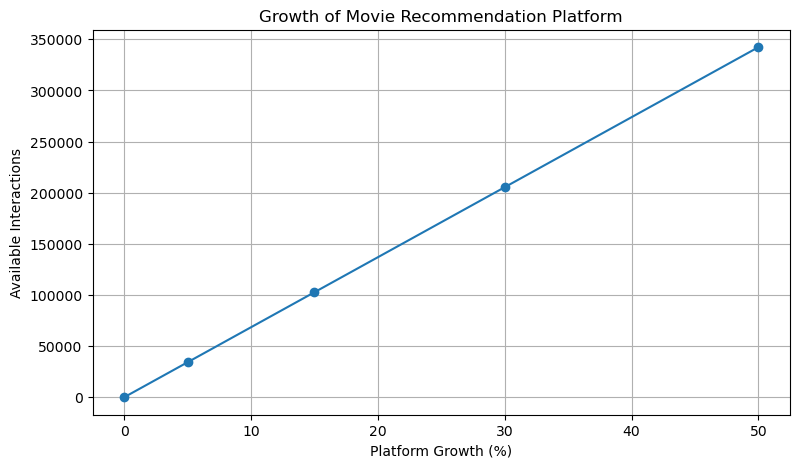

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    stage_summary["growth_percentage"],
    stage_summary["interactions"],
    marker="o"
)

plt.xlabel("Platform Growth (%)")
plt.ylabel("Available Interactions")
plt.title("Growth of Movie Recommendation Platform")
plt.grid(True)

plt.show()

In [44]:
print("Initial stage interactions:", len(growth_stages[0]))
print("Initial stage users:", growth_stages[0]["userID"].nunique())
print("Initial stage movies:", growth_stages[0]["movieID"].nunique())

print("\nFuture test interactions:", len(future_test))

Initial stage interactions: 0
Initial stage users: 0
Initial stage movies: 0

Future test interactions: 171120


In [45]:
stage_summary = pd.DataFrame([
    {
        "growth_percentage": percentage,
        "interactions": len(data),
        "active_users": data["userID"].nunique(),
        "active_movies": data["movieID"].nunique()
    }
    for percentage, data in growth_stages.items()
])

stage_summary

,growth_percentage,interactions,active_users,active_movies
0,0,0,0,0
1,5,34223,132,3008
2,15,102671,263,4836
3,30,205343,414,6879
4,50,342239,661,7958


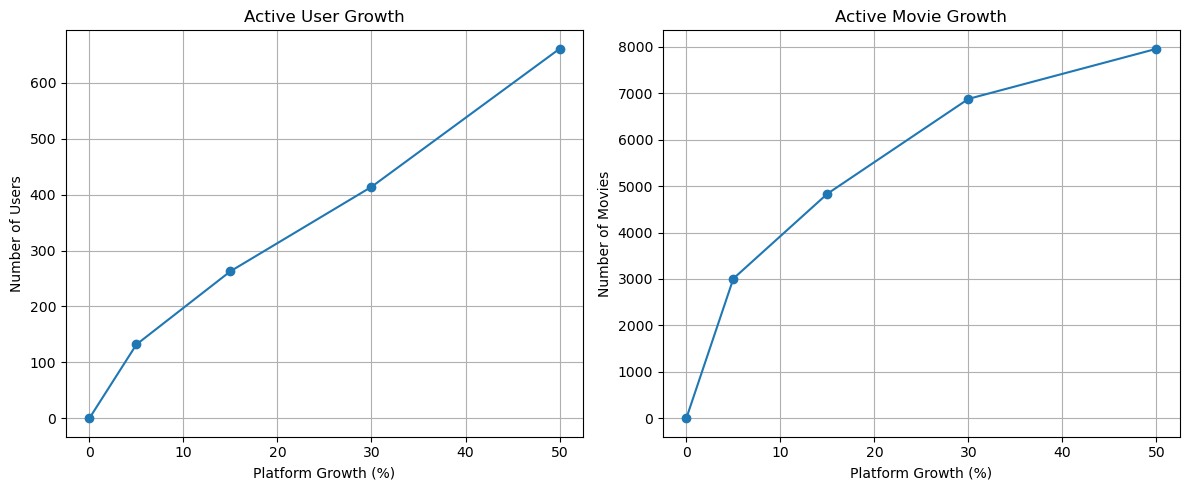

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    stage_summary["growth_percentage"],
    stage_summary["active_users"],
    marker="o"
)
axes[0].set_title("Active User Growth")
axes[0].set_xlabel("Platform Growth (%)")
axes[0].set_ylabel("Number of Users")
axes[0].grid(True)

axes[1].plot(
    stage_summary["growth_percentage"],
    stage_summary["active_movies"],
    marker="o"
)
axes[1].set_title("Active Movie Growth")
axes[1].set_xlabel("Platform Growth (%)")
axes[1].set_ylabel("Number of Movies")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [48]:
(PROJECT_ROOT / "outputs" / "results").mkdir(
    parents=True,
    exist_ok=True
)

In [49]:
stage_summary.to_csv(
    PROJECT_ROOT / "outputs" / "results" /
    "system_growth_summary.csv",
    index=False
)

print("Growth summary saved successfully!")

Growth summary saved successfully!


In [50]:
stage_summary = pd.DataFrame([
    {
        "growth_percentage": percentage,
        "interactions": len(data),
        "active_users": data["userID"].nunique(),
        "active_movies": data["movieID"].nunique()
    }
    for percentage, data in growth_stages.items()
])

In [51]:
stage_summary

,growth_percentage,interactions,active_users,active_movies
0,0,0,0,0
1,5,34223,132,3008
2,15,102671,263,4836
3,30,205343,414,6879
4,50,342239,661,7958


In [52]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

In [53]:
def train_user_cf(stage_data):

    user_ids = stage_data["userID"].unique()
    movie_ids = stage_data["movieID"].unique()

    user_to_index = {
        user_id: idx for idx, user_id in enumerate(user_ids)
    }

    movie_to_index = {
        movie_id: idx for idx, movie_id in enumerate(movie_ids)
    }

    rows = stage_data["userID"].map(user_to_index)
    cols = stage_data["movieID"].map(movie_to_index)

    user_item_matrix = csr_matrix(
        (
            stage_data["rating"].values,
            (rows, cols)
        ),
        shape=(len(user_ids), len(movie_ids))
    )

    return {
        "matrix": user_item_matrix,
        "user_ids": user_ids,
        "movie_ids": movie_ids,
        "user_to_index": user_to_index,
        "movie_to_index": movie_to_index
    }

In [57]:
def recommend_user_cf(
    user_id,
    model,
    top_n=10,
    k=20
):

    if user_id not in model["user_to_index"]:
        return pd.DataFrame()

    matrix = model["matrix"]
    user_index = model["user_to_index"][user_id]

    # Calculate user similarities
    similarities = cosine_similarity(
        matrix[user_index],
        matrix
    ).flatten()

    similarities[user_index] = 0

    # Select top similar users
    neighbor_indices = np.argsort(similarities)[::-1]

    neighbor_indices = [
        idx for idx in neighbor_indices
        if similarities[idx] > 0
    ][:k]

    if not neighbor_indices:
        return pd.DataFrame()

    neighbor_similarities = similarities[neighbor_indices]
    neighbor_matrix = matrix[neighbor_indices]

    # Calculate similarity-weighted rating totals
    weighted_scores = np.asarray(
        neighbor_similarities @ neighbor_matrix
    ).flatten()

    # Sum similarity weights only for users who rated each movie
    weighted_counts = np.asarray(
        neighbor_similarities @ (neighbor_matrix != 0)
    ).flatten()

    # Calculate weighted average ratings
    scores = np.divide(
        weighted_scores,
        weighted_counts,
        out=np.zeros_like(weighted_scores, dtype=float),
        where=weighted_counts > 0
    )

    # Exclude movies already rated by the target user
    rated_movies = set(matrix[user_index].indices)

    candidate_indices = [
        idx for idx in range(len(model["movie_ids"]))
        if idx not in rated_movies and weighted_counts[idx] > 0
    ]

    candidate_indices = sorted(
        candidate_indices,
        key=lambda idx: scores[idx],
        reverse=True
    )[:top_n]

    recommended_ids = [
        model["movie_ids"][idx]
        for idx in candidate_indices
    ]

    recommendations = movie_features[
        movie_features["movieID"].isin(recommended_ids)
    ][["movieID", "title", "genres"]].copy()

    score_lookup = {
        model["movie_ids"][idx]: scores[idx]
        for idx in candidate_indices
    }

    recommendations["score"] = recommendations["movieID"].map(
        score_lookup
    )

    recommendations["source"] = "collaborative_filtering"

    return recommendations.sort_values(
        "score",
        ascending=False
    ).reset_index(drop=True)

In [58]:
cf_model_50 = train_user_cf(growth_stages[50])

print("Collaborative filtering model trained!")
print("Users:", len(cf_model_50["user_ids"]))
print("Movies:", len(cf_model_50["movie_ids"]))
print("Matrix shape:", cf_model_50["matrix"].shape)

Collaborative filtering model trained!
Users: 661
Movies: 7958
Matrix shape: (661, 7958)


In [59]:
test_user_id = int(growth_stages[50]["userID"].iloc[0])

cf_recommendations = recommend_user_cf(
    test_user_id,
    cf_model_50,
    top_n=10
)

print("Test user:", test_user_id)

cf_recommendations

Test user: 51198


,movieID,title,genres,score,source
0,280,Murder in the First,Drama Thriller,5.0,collaborative_filtering
1,322,Swimming with Sharks,Comedy Drama,5.0,collaborative_filtering
2,324,The Sum of Us,Comedy Drama,5.0,collaborative_filtering
3,373,Red Rock West,Thriller,5.0,collaborative_filtering
4,720,Wallace & Gromit: The Best of Aardman Animation,Adventure Animation Comedy,5.0,collaborative_filtering
5,1049,The Ghost and the Darkness,Action Adventure,5.0,collaborative_filtering
6,1171,Bob Roberts,Comedy,5.0,collaborative_filtering
7,1459,Absolute Power,Mystery Thriller,5.0,collaborative_filtering
8,1945,On the Waterfront,Crime Drama,5.0,collaborative_filtering
9,2020,Dangerous Liaisons,Drama Romance,5.0,collaborative_filtering


In [60]:
print("Minimum recommendation score:",
      cf_recommendations["score"].min())

print("Maximum recommendation score:",
      cf_recommendations["score"].max())

Minimum recommendation score: 5.0
Maximum recommendation score: 5.0


In [61]:
print(cf_recommendations[
    ["title", "score"]
].to_string(index=False))

print("\nScore distribution:")
print(cf_recommendations["score"].describe())

print("\nUnique scores:")
print(cf_recommendations["score"].unique())

                                          title  score
                            Murder in the First    5.0
                           Swimming with Sharks    5.0
                                  The Sum of Us    5.0
                                  Red Rock West    5.0
Wallace & Gromit: The Best of Aardman Animation    5.0
                     The Ghost and the Darkness    5.0
                                    Bob Roberts    5.0
                                 Absolute Power    5.0
                              On the Waterfront    5.0
                             Dangerous Liaisons    5.0

Score distribution:
count    10.0
mean      5.0
std       0.0
min       5.0
25%       5.0
50%       5.0
75%       5.0
max       5.0
Name: score, dtype: float64

Unique scores:
[5.]


In [62]:
user_history = growth_stages[50][
    growth_stages[50]["userID"] == test_user_id
]

print("User ID:", test_user_id)
print("Number of ratings:", len(user_history))
print("Average rating:", user_history["rating"].mean())
print("\nRating distribution:")
print(user_history["rating"].value_counts().sort_index())

User ID: 51198
Number of ratings: 200
Average rating: 4.08

Rating distribution:
rating
2.0      3
3.0     26
3.5      6
4.0    104
4.5     20
5.0     41
Name: count, dtype: int64


In [63]:
similarities = cosine_similarity(
    cf_model_50["matrix"][
        cf_model_50["user_to_index"][test_user_id]
    ],
    cf_model_50["matrix"]
).flatten()

similarities[
    cf_model_50["user_to_index"][test_user_id]
] = 0

top_neighbors = np.argsort(similarities)[::-1][:20]

print("Top 20 similarity scores:")
print(similarities[top_neighbors])

Top 20 similarity scores:
[0.40949145 0.40848586 0.39560553 0.39102368 0.38980853 0.38979295
 0.38921342 0.38648472 0.38440232 0.38193549 0.37977284 0.37906942
 0.37801264 0.37788906 0.37777884 0.37067864 0.36889732 0.36812757
 0.36689831 0.36659613]


In [64]:
user_means = growth_stages[50].groupby(
    "userID"
)["rating"].mean()

print(user_means.describe())

count    661.000000
mean       3.497067
std        0.404464
min        1.502299
25%        3.246360
50%        3.508532
75%        3.774194
max        5.000000
Name: rating, dtype: float64


In [65]:
stage_data = growth_stages[50].copy()

stage_data["user_mean"] = stage_data["userID"].map(
    user_means
)

stage_data["centered_rating"] = (
    stage_data["rating"] - stage_data["user_mean"]
)

user_ids = stage_data["userID"].unique()
movie_ids = stage_data["movieID"].unique()

user_to_index = {
    uid: idx for idx, uid in enumerate(user_ids)
}

movie_to_index = {
    mid: idx for idx, mid in enumerate(movie_ids)
}

rows = stage_data["userID"].map(user_to_index)
cols = stage_data["movieID"].map(movie_to_index)

centered_matrix = csr_matrix(
    (
        stage_data["centered_rating"].values,
        (rows, cols)
    ),
    shape=(len(user_ids), len(movie_ids))
)

print("Mean-centred matrix:", centered_matrix.shape)

Mean-centred matrix: (661, 7958)


In [66]:
test_index = user_to_index[test_user_id]

centered_similarities = cosine_similarity(
    centered_matrix[test_index],
    centered_matrix
).flatten()

centered_similarities[test_index] = 0

print("Top 20 mean-centred similarities:")
print(
    np.sort(centered_similarities)[::-1][:20]
)


Top 20 mean-centred similarities:
[0.21327555 0.21139931 0.20220234 0.18677973 0.18638472 0.1850051
 0.18359873 0.17788797 0.17723526 0.17643551 0.17525321 0.17331686
 0.16641927 0.16492964 0.16269776 0.15939467 0.15862939 0.15698598
 0.15318013 0.15249937]


In [67]:
raw_matrix = csr_matrix(
    (stage_data["rating"].values, (rows, cols)),
    shape=(len(user_ids), len(movie_ids))
)

print("Raw interaction matrix:", raw_matrix.shape)

Raw interaction matrix: (661, 7958)


In [75]:
def recommend_mean_centered_cf(user_id, top_n=10, k=20, min_support=2):

    if user_id not in cf_model_50["user_to_index"]:
        print("User not found in this growth stage.")
        return pd.DataFrame()

    target_idx = cf_model_50["user_to_index"][user_id]
    raw_matrix = cf_model_50["matrix"]

    # Calculate similarities using mean-centred ratings
    similarities = cosine_similarity(
        centered_matrix[target_idx],
        centered_matrix
    ).flatten()

    similarities[target_idx] = 0

    # Select top positive-similarity neighbours
    neighbor_indices = np.argsort(similarities)[::-1]
    neighbor_indices = [
        idx for idx in neighbor_indices
        if similarities[idx] > 0
    ][:k]

    if len(neighbor_indices) == 0:
        return pd.DataFrame()

    neighbor_similarities = similarities[neighbor_indices]

    # Get original ratings of neighbours
    neighbor_raw = raw_matrix[neighbor_indices].tocsr()
    neighbor_centered = neighbor_raw.astype(float).copy()

    # Subtract each neighbour's own average rating
    for i, neighbor_idx in enumerate(neighbor_indices):
        neighbor_id = cf_model_50["user_ids"][neighbor_idx]
        mean_rating = user_means.loc[neighbor_id]

        start = neighbor_centered.indptr[i]
        end = neighbor_centered.indptr[i + 1]

        neighbor_centered.data[start:end] -= mean_rating

    # Calculate weighted rating deviations
    weighted_deviations = np.asarray(
        neighbor_similarities.reshape(1, -1) @ neighbor_centered
    ).flatten()

    # Calculate weighted support
    weighted_counts = np.asarray(
        neighbor_similarities.reshape(1, -1) @ (neighbor_raw != 0)
    ).flatten()

    neighbor_support = np.asarray(
        (neighbor_raw != 0).sum(axis=0)
    ).flatten()

    # Calculate predicted ratings
    target_mean = user_means.loc[user_id]

    raw_predictions = np.divide(
        weighted_deviations,
        weighted_counts,
        out=np.zeros_like(weighted_deviations, dtype=float),
        where=weighted_counts > 0
    ) + target_mean

    # Exclude movies already rated by target user
    target_rated = raw_matrix[target_idx].toarray().flatten() != 0

    valid = (
        (weighted_counts > 0) &
        (neighbor_support >= min_support) &
        (~target_rated)
    )

    candidate_indices = np.where(valid)[0]

    if len(candidate_indices) == 0:
        return pd.DataFrame()

    # Sort using unclipped predictions to preserve ranking
    # Rank recommendations using original, unclipped predictions
    ranked_indices = candidate_indices[
        np.argsort(raw_predictions[candidate_indices])[::-1]
    ][:top_n]

    recommendations = pd.DataFrame({
        "movieID": cf_model_50["movie_ids"][ranked_indices],

        # Keep original prediction for analysis
        "raw_prediction": raw_predictions[ranked_indices],

        # Clip only the displayed rating
        "predicted_rating": np.clip(
            raw_predictions[ranked_indices], 0.5, 5.0
    ),

    "neighbor_support": neighbor_support[ranked_indices]
})

    recommendations = recommendations.merge(
        movie_features[["movieID", "title", "genres"]],
        on="movieID",
        how="left"
    )

    return recommendations[
        ["movieID", "title", "genres",
         "predicted_rating", "raw_prediction", "neighbor_support"]
    ].reset_index(drop=True)

In [76]:
centered_recommendations = recommend_mean_centered(
    user_id=test_user_id,
    top_n=10,
    k=20
)

display(centered_recommendations)

print(
    "Unique predicted scores:",
    centered_recommendations["predicted_rating"].nunique()
)

,movieID,title,genres,predicted_rating,neighbor_support
0,230,Dolores Claiborne,Drama Thriller,5.0,3
1,308,Trzy kolory: Bialy,Comedy Drama,5.0,2
2,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy War,5.0,7
3,904,Rear Window,Mystery Thriller,5.0,5
4,1232,Stalker,Drama Mystery Sci-Fi,5.0,3
5,1204,Lawrence of Arabia,Adventure Drama War,5.0,3
6,1223,A Grand Day Out with Wallace and Gromit,Adventure Animation Children Comedy Sci-Fi,5.0,2
7,1094,The Crying Game,Drama Romance War,5.0,2
8,1358,Sling Blade,Drama Thriller,5.0,4
9,741,Kôkaku kidôtai,Animation Sci-Fi,5.0,6


Unique predicted scores: 1


In [77]:
# Recalculate mean-centred similarities for the target user
target_index = user_to_index[test_user_id]

similarities = cosine_similarity(
    centered_matrix[target_index],
    centered_matrix
).flatten()

similarities[target_index] = 0

# Select the 20 most similar positive neighbours
neighbor_indices = np.argsort(similarities)[::-1]
neighbor_indices = [
    idx for idx in neighbor_indices
    if similarities[idx] > 0
][:20]

neighbor_similarities = similarities[neighbor_indices]

# Get original ratings of these neighbours
raw_matrix = cf_model_50["matrix"]
neighbor_raw = raw_matrix[neighbor_indices].tocsr()

# Calculate each neighbour's rating deviations
neighbor_centered = neighbor_raw.astype(float).copy()

for i, neighbor_idx in enumerate(neighbor_indices):
    neighbor_id = cf_model_50["user_ids"][neighbor_idx]
    mean_rating = user_means.loc[neighbor_id]

    start = neighbor_centered.indptr[i]
    end = neighbor_centered.indptr[i + 1]

    neighbor_centered.data[start:end] -= mean_rating

# Calculate weighted deviations
weighted_deviations = np.asarray(
    neighbor_similarities @ neighbor_centered
).flatten()

weighted_counts = np.asarray(
    neighbor_similarities @ (neighbor_raw != 0)
).flatten()

# Calculate predictions BEFORE clipping
target_mean = user_means.loc[test_user_id]

raw_predictions = np.divide(
    weighted_deviations,
    weighted_counts,
    out=np.zeros_like(weighted_deviations, dtype=float),
    where=weighted_counts > 0
) + target_mean

# Exclude movies already rated by the target user
target_rated = raw_matrix[target_index].toarray().flatten() != 0

valid = (weighted_counts > 0) & (~target_rated)

print("Target user's average rating:", target_mean)
print("\nUnclipped prediction statistics:")
print(pd.Series(raw_predictions[valid]).describe())

print("\nPredictions above 5:",
      np.sum(raw_predictions[valid] > 5))

print("Predictions below 0.5:",
      np.sum(raw_predictions[valid] < 0.5))

Target user's average rating: 4.08

Unclipped prediction statistics:
count    1881.000000
mean        3.918983
std         0.776015
min         1.032991
25%         3.511934
50%         4.009275
75%         4.454016
max         6.202977
dtype: float64

Predictions above 5: 89
Predictions below 0.5: 0


In [78]:
cf_recommendations = recommend_mean_centered_cf(
    user_id=test_user_id,
    top_n=10
)

display(cf_recommendations)

print("\nUnique predicted ratings:",
      cf_recommendations["predicted_rating"].nunique())

print("\nPrediction distribution:")
print(cf_recommendations["predicted_rating"].describe())

,movieID,title,genres,predicted_rating,raw_prediction,neighbor_support
0,7982,"Janghwa, Hongryeon",Drama Horror Mystery Thriller,5.0,5.760616,2
1,1094,The Crying Game,Drama Romance War,5.0,5.462122,2
2,3855,Une liaison pornographique,Drama Romance,5.0,5.284924,2
3,1204,Lawrence of Arabia,Adventure Drama War,5.0,5.279754,3
4,1209,C'era una volta il West,Action Drama Western,5.0,5.235020,4
5,5995,The Pianist,Drama War,5.0,5.226366,8
6,8970,Finding Neverland,Drama,5.0,5.217865,3
7,2917,Body Heat,Crime Thriller,5.0,5.212405,2
8,3505,No Way Out,Drama Mystery Thriller,5.0,5.212405,2
9,308,Trzy kolory: Bialy,Comedy Drama,5.0,5.212405,2



Unique predicted ratings: 1

Prediction distribution:
count    10.0
mean      5.0
std       0.0
min       5.0
25%       5.0
50%       5.0
75%       5.0
max       5.0
Name: predicted_rating, dtype: float64


In [79]:
output_dir = PROJECT_ROOT / "outputs" / "results"
output_dir.mkdir(parents=True, exist_ok=True)

cf_recommendations.to_csv(
    output_dir / "system_cf_recommendations_50.csv",
    index=False
)

print("Collaborative filtering recommendations saved.")

Collaborative filtering recommendations saved.


In [80]:
# Select users who have interaction history in the 50% stage
stage_50_users = growth_stages[50]["userID"].unique()

# Select up to 20 users for the experiment
evaluation_users = stage_50_users[:20]

print("Number of evaluation users:", len(evaluation_users))
print("Selected users:", evaluation_users)

Number of evaluation users: 20
Selected users: [51198 29202 32283 36495 28350 57138 35886  9117 10476 17999 18059 19587
 21712 23172 12296 49879 50670 46890 52592 60713]


In [81]:
from scipy.sparse import csr_matrix

def build_stage_cf_model(stage_data):

    user_ids = stage_data["userID"].unique()
    movie_ids = stage_data["movieID"].unique()

    user_to_index = {uid: idx for idx, uid in enumerate(user_ids)}
    movie_to_index = {mid: idx for idx, mid in enumerate(movie_ids)}

    rows = stage_data["userID"].map(user_to_index)
    cols = stage_data["movieID"].map(movie_to_index)

    user_means_stage = stage_data.groupby("userID")["rating"].mean()

    centered_ratings = (
        stage_data["rating"].values
        - stage_data["userID"].map(user_means_stage).values
    )

    centered_matrix_stage = csr_matrix(
        (centered_ratings, (rows, cols)),
        shape=(len(user_ids), len(movie_ids))
    )

    raw_matrix_stage = csr_matrix(
        (stage_data["rating"].values, (rows, cols)),
        shape=(len(user_ids), len(movie_ids))
    )

    return {
        "user_ids": user_ids,
        "movie_ids": movie_ids,
        "user_to_index": user_to_index,
        "movie_to_index": movie_to_index,
        "user_means": user_means_stage,
        "centered_matrix": centered_matrix_stage,
        "raw_matrix": raw_matrix_stage
    }

In [82]:
def recommend_stage_cf(model, user_id, top_n=10, k=20):

    if user_id not in model["user_to_index"]:
        return pd.DataFrame()

    user_idx = model["user_to_index"][user_id]

    similarities = cosine_similarity(
        model["centered_matrix"][user_idx],
        model["centered_matrix"]
    ).flatten()

    similarities[user_idx] = 0

    neighbor_indices = np.argsort(similarities)[::-1]
    neighbor_indices = [
        idx for idx in neighbor_indices
        if similarities[idx] > 0
    ][:k]

    if len(neighbor_indices) == 0:
        return pd.DataFrame()

    neighbor_similarities = similarities[neighbor_indices]

    neighbor_raw = model["raw_matrix"][neighbor_indices].tocsr()
    neighbor_centered = neighbor_raw.astype(float).copy()

    for i, neighbor_idx in enumerate(neighbor_indices):
        neighbor_id = model["user_ids"][neighbor_idx]
        mean_rating = model["user_means"].loc[neighbor_id]

        start = neighbor_centered.indptr[i]
        end = neighbor_centered.indptr[i + 1]

        neighbor_centered.data[start:end] -= mean_rating

    weighted_deviations = np.asarray(
        neighbor_similarities.reshape(1, -1) @ neighbor_centered
    ).flatten()

    weighted_counts = np.asarray(
        neighbor_similarities.reshape(1, -1) @ (neighbor_raw != 0)
    ).flatten()

    support = np.asarray(
        (neighbor_raw != 0).sum(axis=0)
    ).flatten()

    raw_predictions = np.divide(
        weighted_deviations,
        weighted_counts,
        out=np.zeros_like(weighted_deviations, dtype=float),
        where=weighted_counts > 0
    ) + model["user_means"].loc[user_id]

    target_rated = (
        model["raw_matrix"][user_idx].toarray().flatten() != 0
    )

    valid = (
        (weighted_counts > 0)
        & (support >= 2)
        & (~target_rated)
    )

    candidates = np.where(valid)[0]

    ranked = candidates[
        np.argsort(raw_predictions[candidates])[::-1]
    ][:top_n]

    result = pd.DataFrame({
        "movieID": model["movie_ids"][ranked],
        "raw_prediction": raw_predictions[ranked],
        "predicted_rating": np.clip(
            raw_predictions[ranked], 0.5, 5.0
        ),
        "neighbor_support": support[ranked]
    })

    return result.merge(
        movie_features[["movieID", "title", "genres"]],
        on="movieID",
        how="left"
    )

In [83]:
stage_models = {}
stage_recommendations = {}

for percentage, stage_data in growth_stages.items():

    print(f"\nProcessing {percentage}% growth stage...")

    if len(stage_data) == 0:
        print("No interactions. Using content-based recommendations.")
        stage_recommendations[percentage] = {}
        continue

    model = build_stage_cf_model(stage_data)
    stage_models[percentage] = model

    stage_recommendations[percentage] = {}

    for user_id in evaluation_users:

        recommendations = recommend_stage_cf(
            model,
            user_id,
            top_n=10
        )

        stage_recommendations[percentage][user_id] = recommendations

    print("Users processed:", len(evaluation_users))
    print(
        "Users with CF recommendations:",
        sum(
            not rec.empty
            for rec in stage_recommendations[percentage].values()
        )
    )


Processing 0% growth stage...
No interactions. Using content-based recommendations.

Processing 5% growth stage...
Users processed: 20
Users with CF recommendations: 19

Processing 15% growth stage...
Users processed: 20
Users with CF recommendations: 19

Processing 30% growth stage...
Users processed: 20
Users with CF recommendations: 20

Processing 50% growth stage...
Users processed: 20
Users with CF recommendations: 20


In [84]:
stage_results = []

for percentage, user_results in stage_recommendations.items():

    cf_users = sum(
        not rec.empty
        for rec in user_results.values()
    )

    stage_results.append({
        "growth_percentage": percentage,
        "interactions": len(growth_stages[percentage]),
        "active_users": growth_stages[percentage]["userID"].nunique(),
        "active_movies": growth_stages[percentage]["movieID"].nunique(),
        "evaluation_users": len(evaluation_users),
        "users_with_cf_recommendations": cf_users
    })

stage_results_df = pd.DataFrame(stage_results)

display(stage_results_df)

,growth_percentage,interactions,active_users,active_movies,evaluation_users,users_with_cf_recommendations
0,0,0,0,0,20,0
1,5,34223,132,3008,20,19
2,15,102671,263,4836,20,19
3,30,205343,414,6879,20,20
4,50,342239,661,7958,20,20


In [85]:
stage_results = []

for percentage, user_results in stage_recommendations.items():

    cf_users = sum(
        not rec.empty
        for rec in user_results.values()
    )

    stage_results.append({
        "growth_percentage": percentage,
        "interactions": len(growth_stages[percentage]),
        "active_users": growth_stages[percentage]["userID"].nunique(),
        "active_movies": growth_stages[percentage]["movieID"].nunique(),
        "evaluation_users": len(evaluation_users),
        "users_with_cf_recommendations": cf_users
    })

stage_results_df = pd.DataFrame(stage_results)

display(stage_results_df)

,growth_percentage,interactions,active_users,active_movies,evaluation_users,users_with_cf_recommendations
0,0,0,0,0,20,0
1,5,34223,132,3008,20,19
2,15,102671,263,4836,20,19
3,30,205343,414,6879,20,20
4,50,342239,661,7958,20,20


In [86]:
stage_results_df.to_csv(
    output_dir / "system_growth_stage_results.csv",
    index=False
)

In [87]:
# Relevant future interactions for each evaluation user
relevant_test = future_test[
    (future_test["userID"].isin(evaluation_users)) &
    (future_test["rating"] >= 4.0)
].copy()

ground_truth = (
    relevant_test.groupby("userID")["movieID"]
    .apply(set)
    .to_dict()
)

print("Evaluation users:", len(evaluation_users))
print("Users with relevant future interactions:", len(ground_truth))
print("Total relevant interactions:", len(relevant_test))

Evaluation users: 20
Users with relevant future interactions: 13
Total relevant interactions: 327


In [88]:
def precision_at_k(recommended, relevant, k=10):
    if not recommended:
        return 0.0

    hits = len(set(recommended[:k]) & relevant)
    return hits / k


def recall_at_k(recommended, relevant, k=10):
    if not relevant:
        return np.nan

    hits = len(set(recommended[:k]) & relevant)
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):
    if not relevant:
        return np.nan

    relevance = [
        1 if movie_id in relevant else 0
        for movie_id in recommended[:k]
    ]

    dcg = sum(
        rel / np.log2(index + 2)
        for index, rel in enumerate(relevance)
    )

    ideal_length = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(index + 2)
        for index in range(ideal_length)
    )

    return dcg / idcg if idcg > 0 else 0.0

In [89]:
evaluation_rows = []

for percentage, user_results in stage_recommendations.items():

    for user_id in evaluation_users:

        recommendations = user_results.get(
            user_id, pd.DataFrame()
        )

        recommended_ids = (
            recommendations["movieID"].tolist()
            if not recommendations.empty
            else []
        )

        relevant_ids = ground_truth.get(user_id, set())

        evaluation_rows.append({
            "growth_percentage": percentage,
            "userID": user_id,
            "precision@10": precision_at_k(
                recommended_ids, relevant_ids
            ),
            "recall@10": recall_at_k(
                recommended_ids, relevant_ids
            ),
            "ndcg@10": ndcg_at_k(
                recommended_ids, relevant_ids
            )
        })

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df.head(10))

,growth_percentage,userID,precision@10,recall@10,ndcg@10
0,0,51198,0.0,0.0,0.0
1,0,29202,0.0,0.0,0.0
2,0,32283,0.0,0.0,0.0
3,0,36495,0.0,NaN,NaN
4,0,28350,0.0,NaN,NaN
5,0,57138,0.0,0.0,0.0
6,0,35886,0.0,NaN,NaN
7,0,9117,0.0,0.0,0.0
8,0,10476,0.0,NaN,NaN
9,0,17999,0.0,0.0,0.0


In [90]:
metrics_summary = (
    evaluation_df.groupby("growth_percentage")
    .agg({
        "precision@10": "mean",
        "recall@10": "mean",
        "ndcg@10": "mean"
    })
    .reset_index()
)

display(metrics_summary)

metrics_summary.to_csv(
    output_dir / "system_cold_start_metrics.csv",
    index=False
)

,growth_percentage,precision@10,recall@10,ndcg@10
0,0,0.000,0.000000,0.000000
1,5,0.010,0.010117,0.012995
2,15,0.005,0.006993,0.004894
3,30,0.015,0.005565,0.021824
4,50,0.020,0.012605,0.036047


In [91]:
coverage_rows = []

total_catalogue_movies = movie_features["movieID"].nunique()

for percentage, user_results in stage_recommendations.items():

    all_recommended = []

    for recommendations in user_results.values():
        if not recommendations.empty:
            all_recommended.extend(
                recommendations["movieID"].tolist()
            )

    unique_recommended = len(set(all_recommended))

    coverage_rows.append({
        "growth_percentage": percentage,
        "unique_movies_recommended": unique_recommended,
        "catalogue_size": total_catalogue_movies,
        "catalogue_coverage": (
            unique_recommended / total_catalogue_movies
        )
    })

coverage_df = pd.DataFrame(coverage_rows)

display(coverage_df)

,growth_percentage,unique_movies_recommended,catalogue_size,catalogue_coverage
0,0,0,10197,0.000000
1,5,138,10197,0.013533
2,15,148,10197,0.014514
3,30,154,10197,0.015102
4,50,161,10197,0.015789


In [92]:
final_metrics = metrics_summary.merge(
    coverage_df,
    on="growth_percentage"
)

display(final_metrics)

final_metrics.to_csv(
    output_dir / "system_cold_start_final_metrics.csv",
    index=False
)

,growth_percentage,precision@10,recall@10,ndcg@10,unique_movies_recommended,catalogue_size,catalogue_coverage
0,0,0.000,0.000000,0.000000,0,10197,0.000000
1,5,0.010,0.010117,0.012995,138,10197,0.013533
2,15,0.005,0.006993,0.004894,148,10197,0.014514
3,30,0.015,0.005565,0.021824,154,10197,0.015102
4,50,0.020,0.012605,0.036047,161,10197,0.015789


In [94]:
from pathlib import Path

figures_dir = PROJECT_ROOT / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures directory:", figures_dir)
print("Directory exists:", figures_dir.exists())

Figures directory: c:\Hybrid-Movie-Recommendation\outputs\figures
Directory exists: True


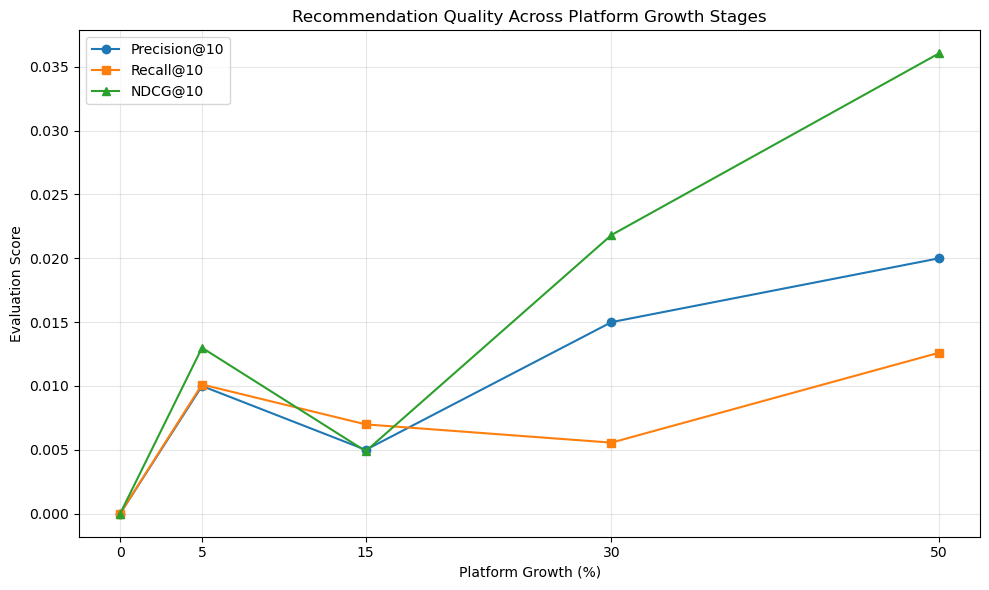

In [95]:
plt.figure(figsize=(10, 6))

plt.plot(
    final_metrics["growth_percentage"],
    final_metrics["precision@10"],
    marker="o",
    label="Precision@10"
)

plt.plot(
    final_metrics["growth_percentage"],
    final_metrics["recall@10"],
    marker="s",
    label="Recall@10"
)

plt.plot(
    final_metrics["growth_percentage"],
    final_metrics["ndcg@10"],
    marker="^",
    label="NDCG@10"
)

plt.xlabel("Platform Growth (%)")
plt.ylabel("Evaluation Score")
plt.title("Recommendation Quality Across Platform Growth Stages")
plt.xticks([0, 5, 15, 30, 50])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs" / "figures" /
    "system_recommendation_quality.png",
    dpi=300
)

plt.show()

In [96]:
plt.savefig(
    figures_dir / "system_recommendation_quality.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

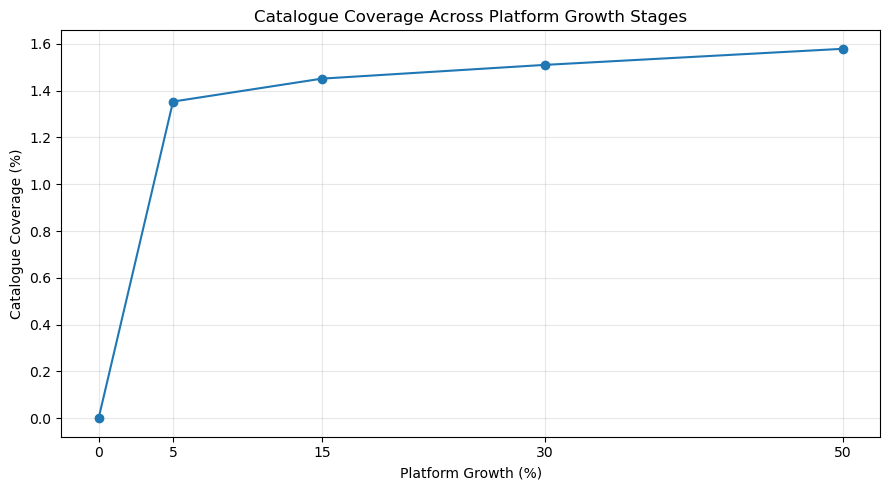

In [97]:
plt.figure(figsize=(9, 5))

plt.plot(
    final_metrics["growth_percentage"],
    final_metrics["catalogue_coverage"] * 100,
    marker="o"
)

plt.xlabel("Platform Growth (%)")
plt.ylabel("Catalogue Coverage (%)")
plt.title("Catalogue Coverage Across Platform Growth Stages")
plt.xticks([0, 5, 15, 30, 50])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs" / "figures" /
    "system_catalogue_coverage.png",
    dpi=300
)

plt.show()

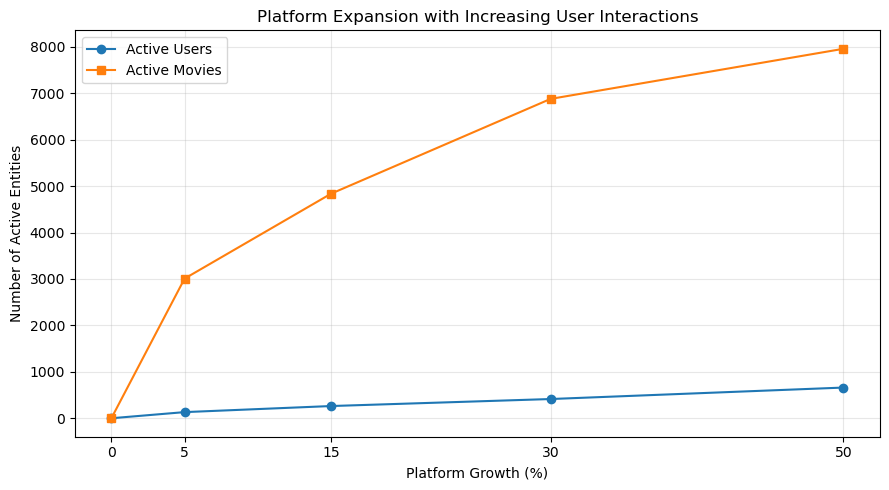

In [98]:
plt.figure(figsize=(9, 5))

plt.plot(
    stage_results_df["growth_percentage"],
    stage_results_df["active_users"],
    marker="o",
    label="Active Users"
)

plt.plot(
    stage_results_df["growth_percentage"],
    stage_results_df["active_movies"],
    marker="s",
    label="Active Movies"
)

plt.xlabel("Platform Growth (%)")
plt.ylabel("Number of Active Entities")
plt.title("Platform Expansion with Increasing User Interactions")
plt.xticks([0, 5, 15, 30, 50])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs" / "figures" /
    "system_platform_growth.png",
    dpi=300
)

plt.show()

In [99]:
plt.savefig(figures_dir / "system_catalogue_coverage.png",
            dpi=300, bbox_inches="tight")

plt.savefig(figures_dir / "system_platform_growth.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [100]:
for file in figures_dir.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

system_catalogue_coverage.png - 14.77 KB
system_platform_growth.png - 14.77 KB
system_recommendation_quality.png - 14.77 KB


In [102]:
print("New-user content function:",
      "recommend_for_new_user" in globals())

print("Mean-centred CF function:",
      "recommend_stage_cf" in globals())

print("Profile builder:",
      "build_user_profile" in globals())

New-user content function: False
Mean-centred CF function: True
Profile builder: False


In [103]:
def build_user_profile(preferences):

    favorite_ids = preferences["favorite_movie_ids"]

    indices = [
        movie_id_to_index[mid]
        for mid in favorite_ids
        if mid in movie_id_to_index
    ]

    if not indices:
        raise ValueError("No valid favourite movie IDs found.")

    user_profile = tfidf_matrix[indices].mean(axis=0)

    return np.asarray(user_profile)


def recommend_for_new_user(preferences, top_n=10):

    user_profile = build_user_profile(preferences)

    similarity_scores = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).flatten()

    recommendations = pd.DataFrame({
        "movieID": movie_features["movieID"].values,
        "similarity_score": similarity_scores
    })

    favorite_ids = preferences["favorite_movie_ids"]

    recommendations = recommendations[
        ~recommendations["movieID"].isin(favorite_ids)
    ]

    recommendations = recommendations.sort_values(
        "similarity_score",
        ascending=False
    ).head(top_n)

    recommendations = recommendations.merge(
        movie_features[["movieID", "title", "genres"]],
        on="movieID",
        how="left"
    )

    return recommendations[
        ["movieID", "title", "genres", "similarity_score"]
    ]

In [105]:
user_preferences = {
    "favorite_movie_ids": [1, 6377, 8961]
}

In [106]:
cold_start_recs = recommend_for_new_user(
    user_preferences,
    top_n=10
)

display(cold_start_recs)

cold_start_recs.to_csv(
    output_dir / "system_cold_start_content_recommendations_0.csv",
    index=False
)

print("Recommendations saved successfully.")

,movieID,title,genres,similarity_score
0,3114,Toy Story,Adventure Animation Children Comedy Fantasy,0.516928
1,50872,Ratatouille,Animation Children Comedy Fantasy,0.416548
2,2355,A Bug's Life,Adventure Animation Children Comedy,0.413174
3,2018,Bambi,Animation Children Drama,0.397845
4,2080,Lady and the Tramp,Animation Children Comedy Musical Romance,0.376228
5,596,Pinocchio,Animation Children Fantasy Musical,0.361412
6,1282,Fantasia,Animation Children Fantasy Musical,0.360632
7,4886,"Monsters, Inc.",Animation Children Comedy Fantasy,0.359873
8,45517,Cars,Animation Children Comedy Fantasy,0.352241
9,40339,Chicken Little,Action Adventure Animation Children Comedy Sci-Fi,0.348473


Recommendations saved successfully.


In [107]:
print(
    (output_dir / "system_cold_start_content_recommendations_0.csv").exists()
)

True


system_catalogue_coverage.png Size: (1980, 1499) File size: 15128 bytes


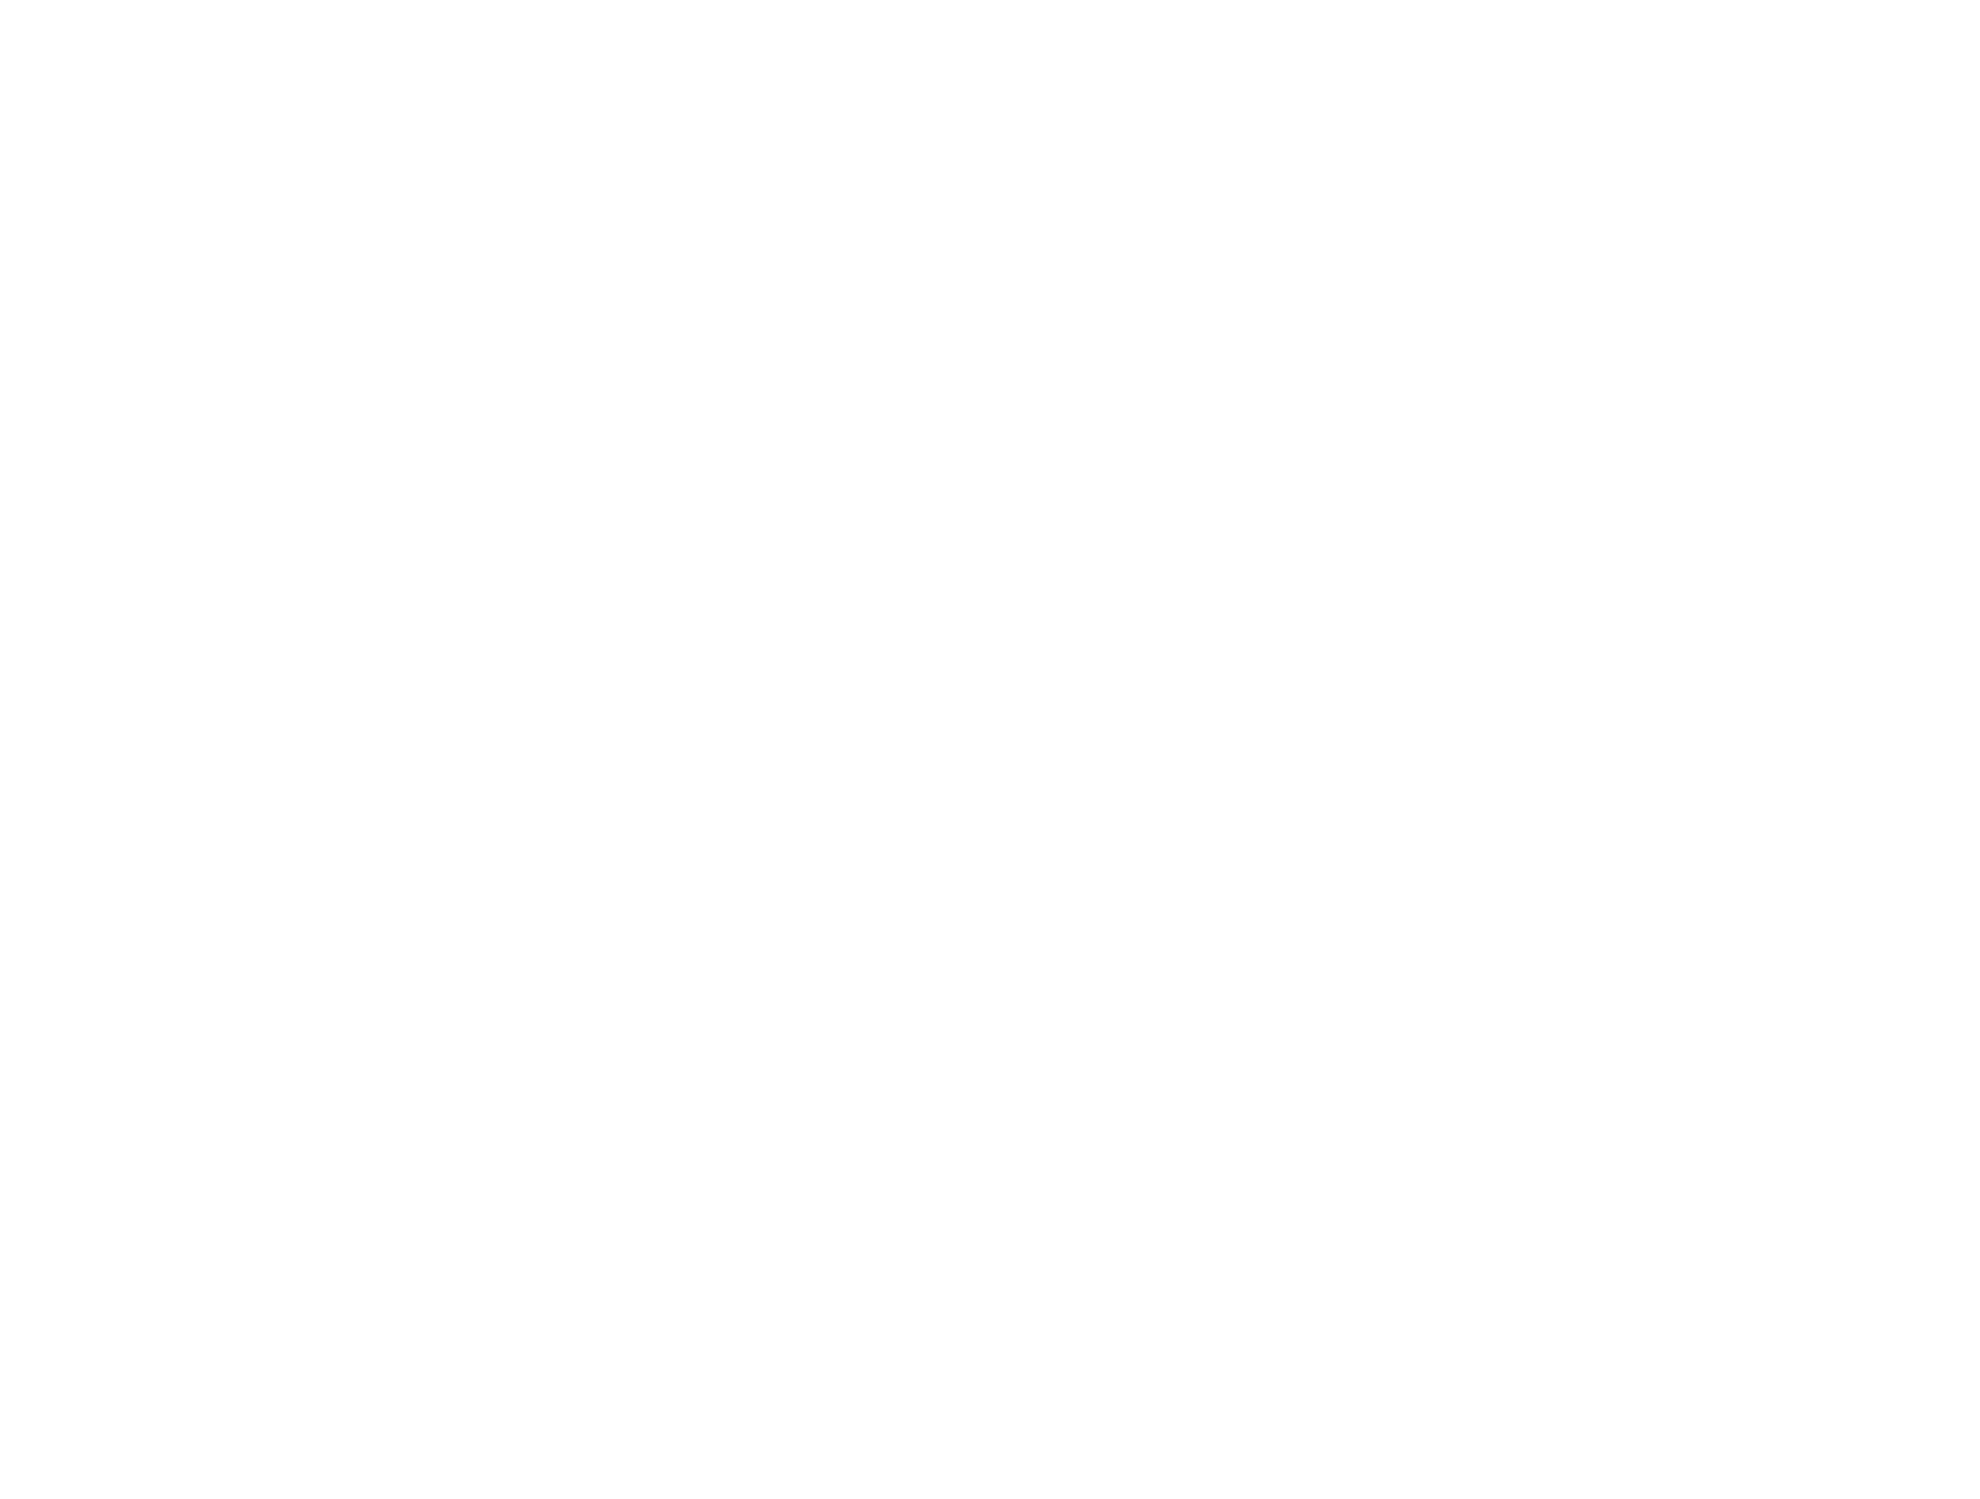

system_platform_growth.png Size: (1980, 1499) File size: 15128 bytes


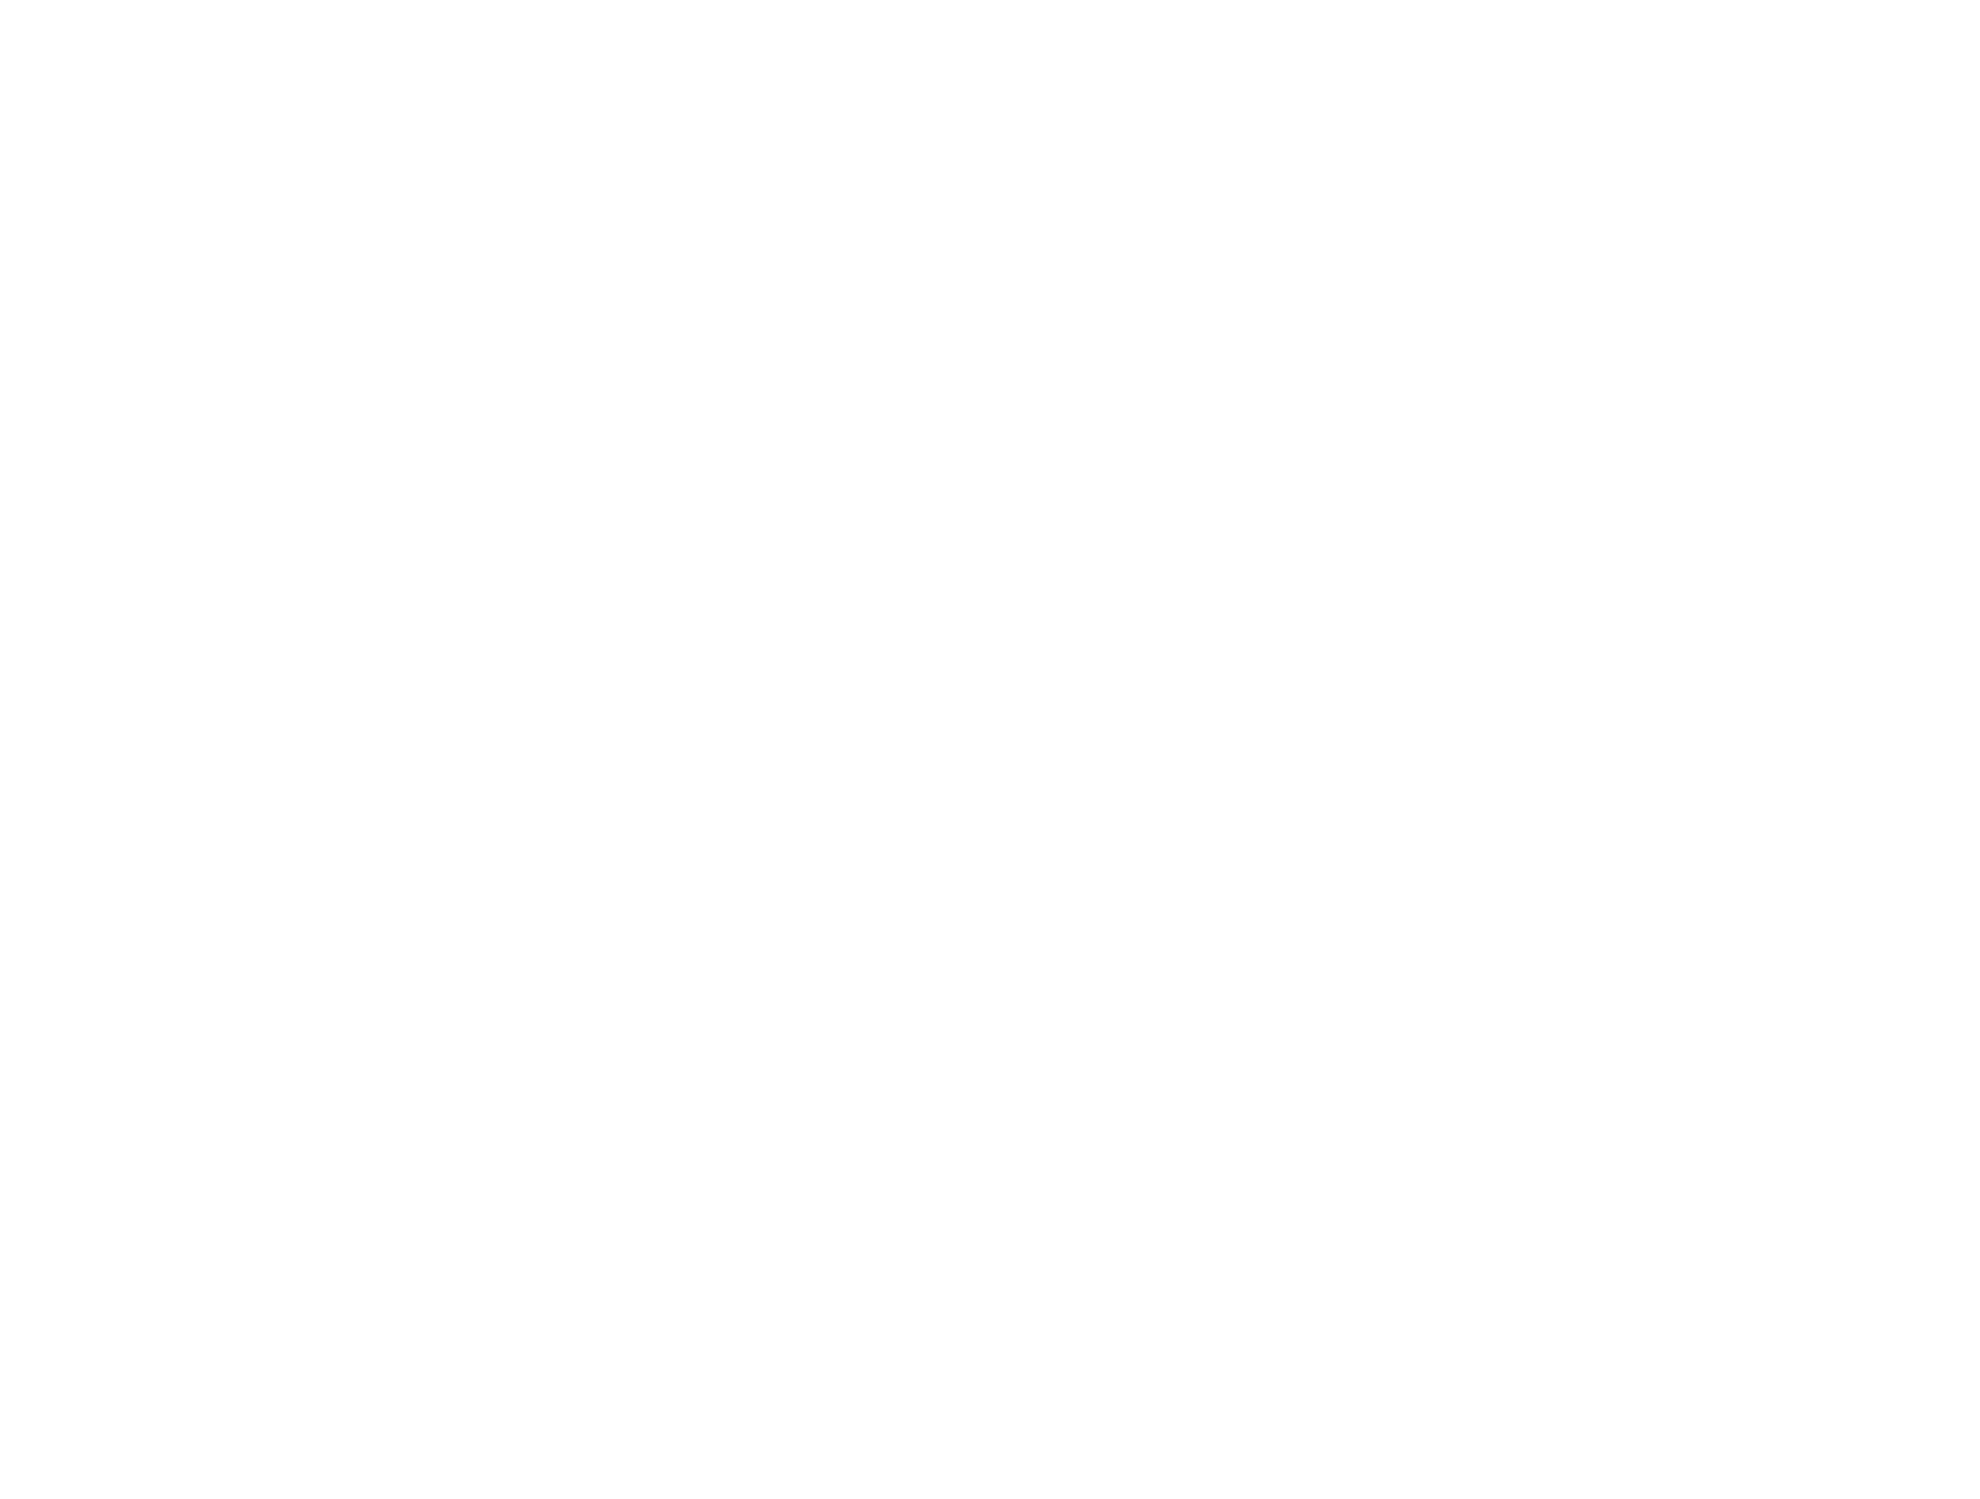

system_recommendation_quality.png Size: (1980, 1499) File size: 15128 bytes


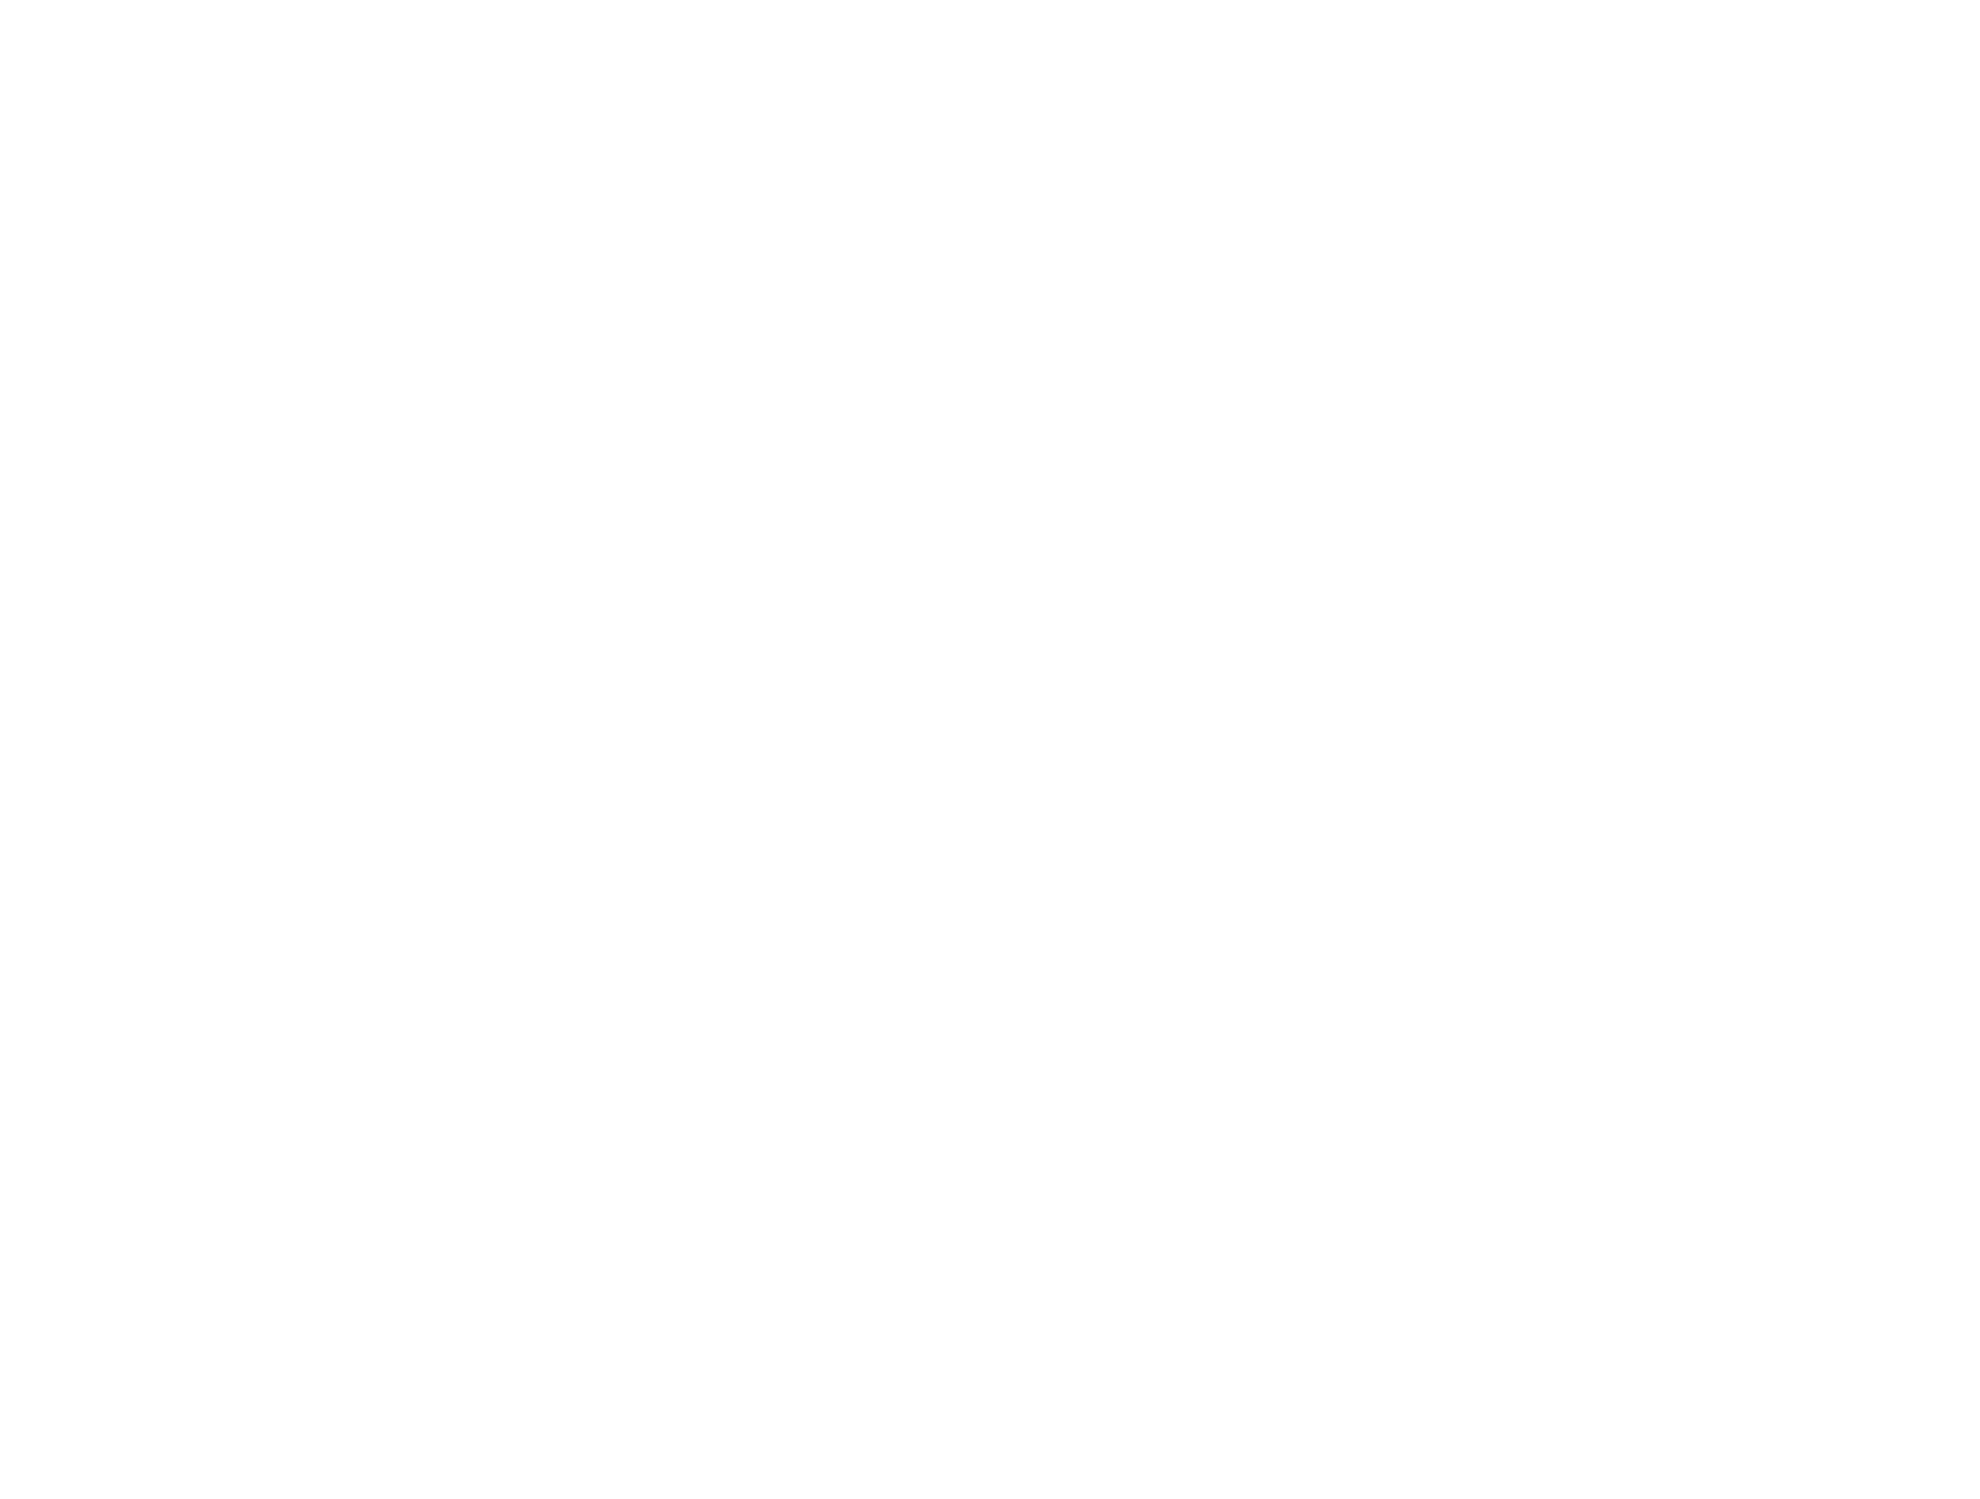

In [108]:
from PIL import Image
from pathlib import Path

figures_dir = PROJECT_ROOT / "outputs" / "figures"

for file in figures_dir.glob("*.png"):
    img = Image.open(file)
    print(
        file.name,
        "Size:", img.size,
        "File size:", file.stat().st_size, "bytes"
    )
    display(img)

In [109]:
plt.figure(figsize=(10, 6))

# Your plotting commands here

plt.tight_layout()

plt.savefig(
    figures_dir / "system_recommendation_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

<Figure size 1000x600 with 0 Axes>

In [110]:
print("final_metrics:", final_metrics.shape)
print("coverage_df:", coverage_df.shape)

display(final_metrics)
display(coverage_df)

final_metrics: (5, 7)
coverage_df: (5, 4)


,growth_percentage,precision@10,recall@10,ndcg@10,unique_movies_recommended,catalogue_size,catalogue_coverage
0,0,0.000,0.000000,0.000000,0,10197,0.000000
1,5,0.010,0.010117,0.012995,138,10197,0.013533
2,15,0.005,0.006993,0.004894,148,10197,0.014514
3,30,0.015,0.005565,0.021824,154,10197,0.015102
4,50,0.020,0.012605,0.036047,161,10197,0.015789


,growth_percentage,unique_movies_recommended,catalogue_size,catalogue_coverage
0,0,0,10197,0.000000
1,5,138,10197,0.013533
2,15,148,10197,0.014514
3,30,154,10197,0.015102
4,50,161,10197,0.015789


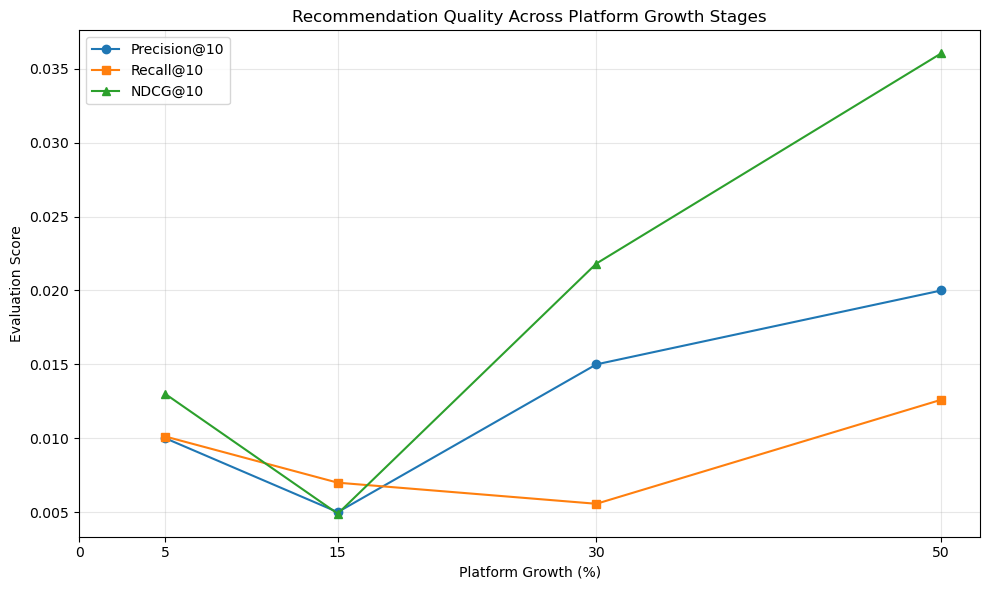

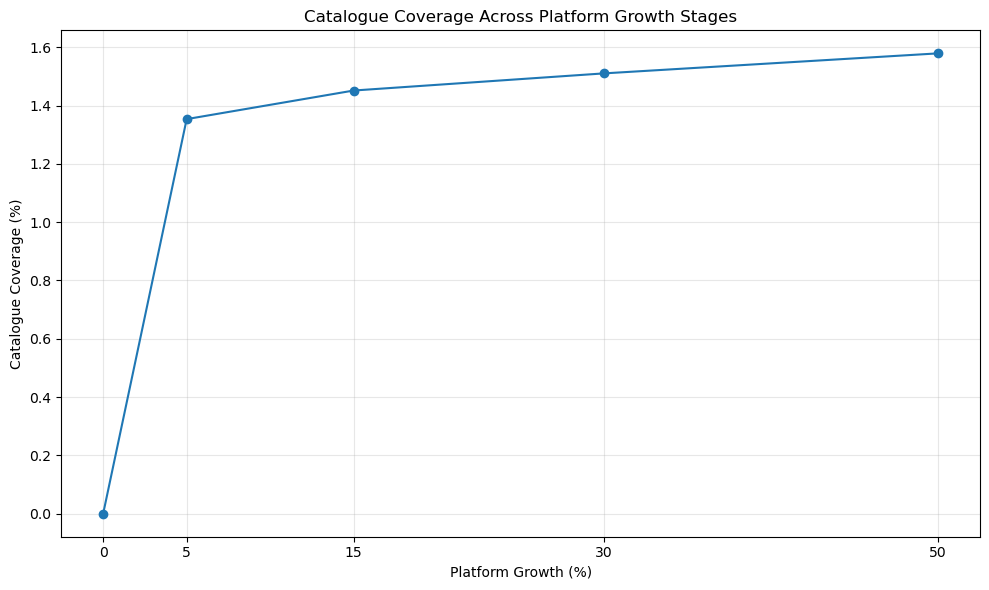

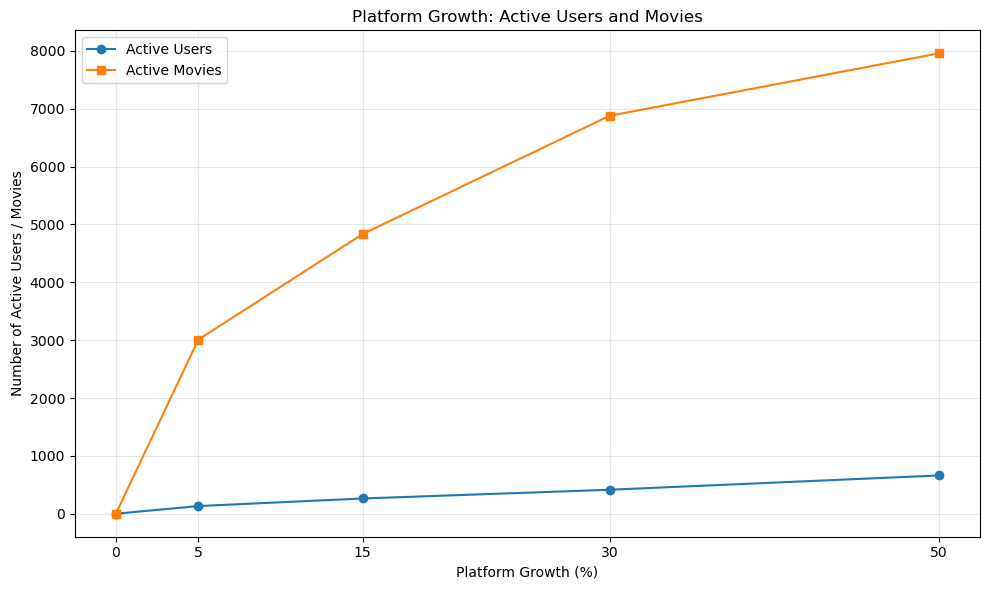


CHART FILES SAVED SUCCESSFULLY:
system_catalogue_coverage.png - 129.66 KB
system_platform_growth.png - 160.83 KB
system_recommendation_quality.png - 229.08 KB


In [111]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure output folder exists
figures_dir = PROJECT_ROOT / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# -----------------------------------------
# CHART 1: Recommendation Quality
# -----------------------------------------

plot_metrics = final_metrics.copy()

# CF is unavailable at 0% platform growth.
# Use NaN rather than showing misleading zero quality.
plot_metrics.loc[
    plot_metrics["growth_percentage"] == 0,
    ["precision@10", "recall@10", "ndcg@10"]
] = np.nan

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(plot_metrics["growth_percentage"],
        plot_metrics["precision@10"],
        marker="o", label="Precision@10")

ax.plot(plot_metrics["growth_percentage"],
        plot_metrics["recall@10"],
        marker="s", label="Recall@10")

ax.plot(plot_metrics["growth_percentage"],
        plot_metrics["ndcg@10"],
        marker="^", label="NDCG@10")

ax.set_title("Recommendation Quality Across Platform Growth Stages")
ax.set_xlabel("Platform Growth (%)")
ax.set_ylabel("Evaluation Score")
ax.set_xticks([0, 5, 15, 30, 50])
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    figures_dir / "system_recommendation_quality.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# -----------------------------------------
# CHART 2: Catalogue Coverage
# -----------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

coverage_percent = final_metrics["catalogue_coverage"] * 100

ax.plot(
    final_metrics["growth_percentage"],
    coverage_percent,
    marker="o"
)

ax.set_title("Catalogue Coverage Across Platform Growth Stages")
ax.set_xlabel("Platform Growth (%)")
ax.set_ylabel("Catalogue Coverage (%)")
ax.set_xticks([0, 5, 15, 30, 50])
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    figures_dir / "system_catalogue_coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# -----------------------------------------
# CHART 3: Platform Growth
# -----------------------------------------

growth_summary = []

for percentage, stage_data in growth_stages.items():
    growth_summary.append({
        "growth_percentage": percentage,
        "active_users": stage_data["userID"].nunique(),
        "active_movies": stage_data["movieID"].nunique()
    })

growth_df = pd.DataFrame(growth_summary)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    growth_df["growth_percentage"],
    growth_df["active_users"],
    marker="o",
    label="Active Users"
)

ax.plot(
    growth_df["growth_percentage"],
    growth_df["active_movies"],
    marker="s",
    label="Active Movies"
)

ax.set_title("Platform Growth: Active Users and Movies")
ax.set_xlabel("Platform Growth (%)")
ax.set_ylabel("Number of Active Users / Movies")
ax.set_xticks([0, 5, 15, 30, 50])
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    figures_dir / "system_platform_growth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# -----------------------------------------
# VERIFY SAVED PNG FILES
# -----------------------------------------

print("\nCHART FILES SAVED SUCCESSFULLY:")

for file in figures_dir.glob("system_*.png"):
    print(f"{file.name} - {file.stat().st_size / 1024:.2f} KB")